In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap
import joblib
import logging
from functools import partial
from dataclasses import dataclass
from typing import Dict, List, Tuple, Any
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.preprocessing import StandardScaler
from config.settings import ROOT_DIR

# Пути к файлам
DATA_PROC_DIR = ROOT_DIR / "data" / "processed"
OUTPUT_DIR    = ROOT_DIR / "output"

# Гиперпараметры
TEST_SIZE = 0.2
N_SPLITS = 3
OPTUNA_SEED = 42
N_TRIALS = 50  # число испытаний Optuna
SHAP_BACKGROUND_SIZE = 100
CUMULATIVE_IMPORTANCE_THRESHOLD = 0.90

# Настройка логирования
optuna.logging.set_verbosity(optuna.logging.WARNING)
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logger = logging.getLogger(__name__)

In [2]:
# Вспомогательные классы и функции (аналогично классическому ноутбуку)
@dataclass
class TrainTestData:
    X_train: np.ndarray
    y_train: np.ndarray
    X_test:  np.ndarray
    y_test:  np.ndarray

def create_tpe_study() -> optuna.Study:
    return optuna.create_study(direction="minimize",
                               sampler=optuna.samplers.TPESampler(seed=OPTUNA_SEED),
                               pruner=optuna.pruners.HyperbandPruner())

def test_plot(y_pred, y_test, title="Сравнение фактических и предсказанных значений"):
    plot_df = pd.DataFrame({"Date": y_test.index, "True": y_test.values, "Pred": y_pred})
    plt.figure(figsize=(12,6))
    sns.lineplot(data=plot_df, x="Date", y="True", color="blue", label="Фактические")
    sns.lineplot(data=plot_df, x="Date", y="Pred", color="red", marker="o", label="Предсказанные")
    plt.title(title); plt.xlabel("Дата"); plt.ylabel("Цена закрытия")
    plt.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

def evaluate_model(model, X_test, y_test, device='cpu'):
    model.eval()
    with torch.no_grad():
        X_t = torch.tensor(X_test, dtype=torch.float32).to(device)
        pred = model(X_t).cpu().numpy().flatten()
    mape = mean_absolute_percentage_error(y_test, pred)
    print(f"MAPE: {mape:.6f}")
    return pred

In [3]:
def build_sequences_with_context(X_prev, y_prev, X_target, y_target, window):
    """
    Строит последовательности так, чтобы для первого предсказания в X_target
    использовался хвост X_prev длиной window (контекст из прошлого блока).

    Возвращает:
        X_seq, y_seq — общий массив последовательностей,
        target_start — индекс первой последовательности, чей таргет относится к X_target.
    """
    if len(X_prev) < window:
        raise ValueError("Недостаточно наблюдений в предыдущем блоке для контекста")
    X_combined = np.concatenate([X_prev, X_target], axis=0)
    y_combined = np.concatenate([y_prev, y_target], axis=0)
    n_seq = len(X_combined) - window
    X_seq = np.stack([X_combined[i:i + window] for i in range(n_seq)])
    y_seq = y_combined[window:]
    target_start = len(X_prev) - window  # первая последовательность, чей таргет — в target
    return X_seq, y_seq, target_start

In [4]:
# Загрузка данных
df_features = pd.read_parquet(DATA_PROC_DIR / "stable_features.parquet")
X, y = df_features.drop("Close", axis=1), df_features["Close"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, shuffle=False)

# Масштабирование
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

train_test_data = TrainTestData(X_train_scaled, y_train.values, X_test_scaled, y_test.values)
feature_names = X.columns.tolist()

# Модели нейронных сетей (PyTorch)

In [5]:
class DNN(nn.Module):
    def __init__(self, input_dim, layer_sizes, dropout_rate=0.0):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for size in layer_sizes:
            layers.append(nn.Linear(prev_dim, size))
            layers.append(nn.ReLU())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            prev_dim = size
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

class LSTMNet(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers=1, dropout=0.0, bidirectional=False):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_size, num_layers,
                            batch_first=True, dropout=dropout, bidirectional=bidirectional)
        self.fc = nn.Linear(hidden_size * (2 if bidirectional else 1), 1)

    def forward(self, x):
        # x: (batch, seq_len, features)
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # последний выход
        return self.fc(out).squeeze(-1)

class GRUNet(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers=1, dropout=0.0, bidirectional=False):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_size, num_layers,
                          batch_first=True, dropout=dropout, bidirectional=bidirectional)
        self.fc = nn.Linear(hidden_size * (2 if bidirectional else 1), 1)

    def forward(self, x):
        out, _ = self.gru(x)
        out = out[:, -1, :]
        return self.fc(out).squeeze(-1)

# Функции обучения и кросс-валидации для PyTorch моделей

In [6]:
def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for Xb, yb in dataloader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = model(Xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * Xb.size(0)
    return total_loss / len(dataloader.dataset)

def evaluate_loss(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for Xb, yb in dataloader:
            Xb, yb = Xb.to(device), yb.to(device)
            pred = model(Xb)
            loss = criterion(pred, yb)
            total_loss += loss.item() * Xb.size(0)
    return total_loss / len(dataloader.dataset)

def create_dataloader(X, y, batch_size, shuffle=False):
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32),
                            torch.tensor(y, dtype=torch.float32))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

def model_time_series_validation_pytorch(model_class, train_test_data: TrainTestData,
                                         params: Dict, device='cpu') -> float:
    X_train, y_train = train_test_data.X_train, train_test_data.y_train
    X_test, y_test = train_test_data.X_test, train_test_data.y_test
    tscv = TimeSeriesSplit(n_splits=N_SPLITS)

    is_recurrent = model_class in (LSTMNet, GRUNet)
    window = params.get('window_size', 0) if is_recurrent else 0

    fold_scores = []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        if is_recurrent:
            if len(X_tr) <= window + 1:
                continue
            X_seq, y_seq, val_start = build_sequences_with_context(
                X_tr, y_tr, X_val, y_val, window)
            X_tr_seq, y_tr_seq = X_seq[:val_start], y_seq[:val_start]
            X_val_seq, y_val_seq = X_seq[val_start:], y_seq[val_start:]
            if len(X_tr_seq) == 0 or len(X_val_seq) == 0:
                continue
            model = model_class(
                input_dim=X_tr_seq.shape[2],
                hidden_size=params['hidden_size'],
                num_layers=params.get('num_layers', 1),
                dropout=params.get('dropout', 0.0),
                bidirectional=params.get('bidirectional', False),
            ).to(device)
            train_loader = create_dataloader(X_tr_seq, y_tr_seq, params['batch_size'], shuffle=True)
            val_loader = create_dataloader(X_val_seq, y_val_seq, params['batch_size'], shuffle=False)
        else:
            model = DNN(
                input_dim=X_tr.shape[1],
                layer_sizes=params['layer_sizes'],
                dropout_rate=params.get('dropout', 0.0),
            ).to(device)
            train_loader = create_dataloader(X_tr, y_tr, params['batch_size'], shuffle=True)
            val_loader = create_dataloader(X_val, y_val, params['batch_size'], shuffle=False)

        optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'])
        criterion = nn.MSELoss()

        epochs = params.get('epochs', 50)
        for epoch in range(epochs):
            train_epoch(model, train_loader, optimizer, criterion, device)

        # Оценка фолда
        model.eval()
        with torch.no_grad():
            if is_recurrent:
                pred = model(torch.tensor(X_val_seq, dtype=torch.float32).to(device)).cpu().numpy().flatten()
                fold_mape = mean_absolute_percentage_error(y_val_seq, pred)
            else:
                pred = model(torch.tensor(X_val, dtype=torch.float32).to(device)).cpu().numpy().flatten()
                fold_mape = mean_absolute_percentage_error(y_val, pred)
        fold_scores.append(fold_mape)

    if not fold_scores:
        return 1.0
    train_error = float(np.mean(fold_scores))

    # Финальное обучение на полном train и оценка на тесте с контекстом
    if is_recurrent:
        X_seq, y_seq, test_start = build_sequences_with_context(
            X_train, y_train, X_test, y_test, window)
        X_train_seq, y_train_seq = X_seq[:test_start], y_seq[:test_start]
        X_test_seq, y_test_seq = X_seq[test_start:], y_seq[test_start:]
        model = model_class(
            input_dim=X_train_seq.shape[2],
            hidden_size=params['hidden_size'],
            num_layers=params.get('num_layers', 1),
            dropout=params.get('dropout', 0.0),
            bidirectional=params.get('bidirectional', False),
        ).to(device)
        train_loader = create_dataloader(X_train_seq, y_train_seq, params['batch_size'], shuffle=True)
        X_eval, y_eval = X_test_seq, y_test_seq
    else:
        model = DNN(
            input_dim=X_train.shape[1],
            layer_sizes=params['layer_sizes'],
            dropout_rate=params.get('dropout', 0.0),
        ).to(device)
        train_loader = create_dataloader(X_train, y_train, params['batch_size'], shuffle=True)
        X_eval, y_eval = X_test, y_test

    optimizer = optim.Adam(model.parameters(), lr=params['learning_rate'])
    criterion = nn.MSELoss()
    for epoch in range(params.get('epochs', 50)):
        train_epoch(model, train_loader, optimizer, criterion, device)

    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(X_eval, dtype=torch.float32).to(device)).cpu().numpy().flatten()
        test_error = mean_absolute_percentage_error(y_eval, pred)

    print(f"Train error: {train_error:.6f}; Test error: {test_error:.6f}")
    print(params)
    return train_error

# Оптимизация гиперпараметров с Optuna

In [7]:
def dnn_objective(trial: optuna.Trial, train_test_data: TrainTestData, device='cpu') -> float:
    # Гиперпараметры
    n_layers = trial.suggest_int('n_layers', 1, 3)
    layer_sizes = []
    for i in range(n_layers):
        layer_sizes.append(trial.suggest_int(f'layer_{i}_size', 16, 128, step=16))
    params = {
        'layer_sizes': layer_sizes,
        'dropout': trial.suggest_float('dropout', 0.0, 0.5),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [16, 32, 64, 128]),
        'epochs': 30
    }
    return model_time_series_validation_pytorch(DNN, train_test_data, params, device)

def lstm_objective(trial: optuna.Trial, train_test_data: TrainTestData, device='cpu') -> float:
    params = {
        'window_size': trial.suggest_int('window_size', 5, 20),
        'hidden_size': trial.suggest_int('hidden_size', 16, 128, step=16),
        'num_layers': trial.suggest_int('num_layers', 2, 3),
        'dropout': trial.suggest_float('dropout', 0.0, 0.5),
        'bidirectional': trial.suggest_categorical('bidirectional', [True, False]),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [16, 32, 64, 128]),
        'epochs': 30
    }
    return model_time_series_validation_pytorch(LSTMNet, train_test_data, params, device)

def gru_objective(trial: optuna.Trial, train_test_data: TrainTestData, device='cpu') -> float:
    params = {
        'window_size': trial.suggest_int('window_size', 5, 20),
        'hidden_size': trial.suggest_int('hidden_size', 16, 128, step=16),
        'num_layers': trial.suggest_int('num_layers', 2, 3),
        'dropout': trial.suggest_float('dropout', 0.0, 0.5),
        'bidirectional': trial.suggest_categorical('bidirectional', [True, False]),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [16, 32, 64, 128]),
        'epochs': 30
    }
    return model_time_series_validation_pytorch(GRUNet, train_test_data, params, device)

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# DNN
dnn_study = create_tpe_study()
dnn_study.optimize(partial(dnn_objective, train_test_data=train_test_data, device=device),
                   n_trials=N_TRIALS, show_progress_bar=True)

# LSTM
lstm_study = create_tpe_study()
lstm_study.optimize(partial(lstm_objective, train_test_data=train_test_data, device=device),
                    n_trials=N_TRIALS, show_progress_bar=True)

# GRU
gru_study = create_tpe_study()
gru_study.optimize(partial(gru_objective, train_test_data=train_test_data, device=device),
                   n_trials=N_TRIALS, show_progress_bar=True)

Using device: cpu


  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.830609; Test error: 0.345818
{'layer_sizes': [128, 96], 'dropout': 0.2993292420985183, 'learning_rate': 0.0002051338263087451, 'batch_size': 64, 'epochs': 30}
Train error: 0.580487; Test error: 0.384457
{'layer_sizes': [16, 128, 112], 'dropout': 0.10616955533913808, 'learning_rate': 0.0002310201887845295, 'batch_size': 64, 'epochs': 30}
Train error: 0.978767; Test error: 0.702812
{'layer_sizes': [80], 'dropout': 0.06974693032602092, 'learning_rate': 0.0003839629299804173, 'batch_size': 64, 'epochs': 30}
Train error: 0.976109; Test error: 0.774754
{'layer_sizes': [80, 16], 'dropout': 0.3037724259507192, 'learning_rate': 0.00021930485556643703, 'batch_size': 64, 'epochs': 30}
Train error: 0.995324; Test error: 0.932825
{'layer_sizes': [16], 'dropout': 0.34211651325607845, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.836109; Test error: 0.293947
{'layer_sizes': [96], 'dropout': 0.15585553804470548, 'learning_rate': 0.00109682172075

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.814062; Test error: 0.703300
{'window_size': 10, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.2993292420985183, 'bidirectional': True, 'learning_rate': 0.00013066739238053285, 'batch_size': 16, 'epochs': 30}
Train error: 0.826700; Test error: 0.690574
{'window_size': 20, 'hidden_size': 112, 'num_layers': 2, 'dropout': 0.09091248360355031, 'bidirectional': False, 'learning_rate': 0.0011207606211860567, 'batch_size': 64, 'epochs': 30}
Train error: 0.784319; Test error: 0.657263
{'window_size': 9, 'hidden_size': 48, 'num_layers': 2, 'dropout': 0.3925879806965068, 'bidirectional': False, 'learning_rate': 0.0015304852121831463, 'batch_size': 32, 'epochs': 30}
Train error: 0.907034; Test error: 0.855055
{'window_size': 20, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.15230688458668534, 'bidirectional': False, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.346252; Test error: 0.055840
{'window_size': 9, 'hidden_size': 96, 'num_

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.868184; Test error: 0.667841
{'window_size': 10, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.2993292420985183, 'bidirectional': True, 'learning_rate': 0.00013066739238053285, 'batch_size': 16, 'epochs': 30}
Train error: 0.923290; Test error: 0.717560
{'window_size': 20, 'hidden_size': 112, 'num_layers': 2, 'dropout': 0.09091248360355031, 'bidirectional': False, 'learning_rate': 0.0011207606211860567, 'batch_size': 64, 'epochs': 30}
Train error: 0.889230; Test error: 0.661572
{'window_size': 9, 'hidden_size': 48, 'num_layers': 2, 'dropout': 0.3925879806965068, 'bidirectional': False, 'learning_rate': 0.0015304852121831463, 'batch_size': 32, 'epochs': 30}
Train error: 0.950630; Test error: 0.855739
{'window_size': 20, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.15230688458668534, 'bidirectional': False, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.384125; Test error: 0.026115
{'window_size': 9, 'hidden_size': 96, 'num_

# Обучение лучших моделей на полных данных и оценка

In [9]:
def train_best_model(model_class, best_params, train_test_data, device):
    X_train, y_train = train_test_data.X_train, train_test_data.y_train
    X_test, y_test = train_test_data.X_test, train_test_data.y_test

    is_recurrent = model_class in (LSTMNet, GRUNet)
    if is_recurrent:
        window = best_params['window_size']
        X_seq, y_seq, test_start = build_sequences_with_context(
            X_train, y_train, X_test, y_test, window)
        X_train_use, y_train_use = X_seq[:test_start], y_seq[:test_start]
        X_test_use, y_test_use = X_seq[test_start:], y_seq[test_start:]
        model = model_class(
            input_dim=X_train_use.shape[2],
            hidden_size=best_params['hidden_size'],
            num_layers=best_params.get('num_layers', 1),
            dropout=best_params.get('dropout', 0.0),
            bidirectional=best_params.get('bidirectional', False),
        ).to(device)
    else:
        n_layers = best_params['n_layers']
        layer_sizes = [best_params[f'layer_{i}_size'] for i in range(n_layers)]
        model = model_class(
            input_dim=X_train.shape[1],
            layer_sizes=layer_sizes,
            dropout_rate=best_params.get('dropout', 0.0),
        ).to(device)
        X_train_use, y_train_use = X_train, y_train
        X_test_use, y_test_use = X_test, y_test

    train_loader = create_dataloader(X_train_use, y_train_use, best_params['batch_size'], shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=best_params['learning_rate'])
    criterion = nn.MSELoss()

    for epoch in range(best_params.get('epochs', 50)):
        train_epoch(model, train_loader, optimizer, criterion, device)

    model.eval()
    with torch.no_grad():
        pred = model(torch.tensor(X_test_use, dtype=torch.float32).to(device)).cpu().numpy().flatten()
    mape = mean_absolute_percentage_error(y_test_use, pred)
    print(f"Final MAPE: {mape:.6f}")
    return model, pred, y_test_use

In [10]:
dnn_model, dnn_pred, dnn_y = train_best_model(DNN, dnn_study.best_params, train_test_data, device)
lstm_model, lstm_pred, lstm_y = train_best_model(LSTMNet, lstm_study.best_params, train_test_data, device)
gru_model, gru_pred, gru_y = train_best_model(GRUNet, gru_study.best_params, train_test_data, device)

Final MAPE: 0.020499
Final MAPE: 0.038668
Final MAPE: 0.027441


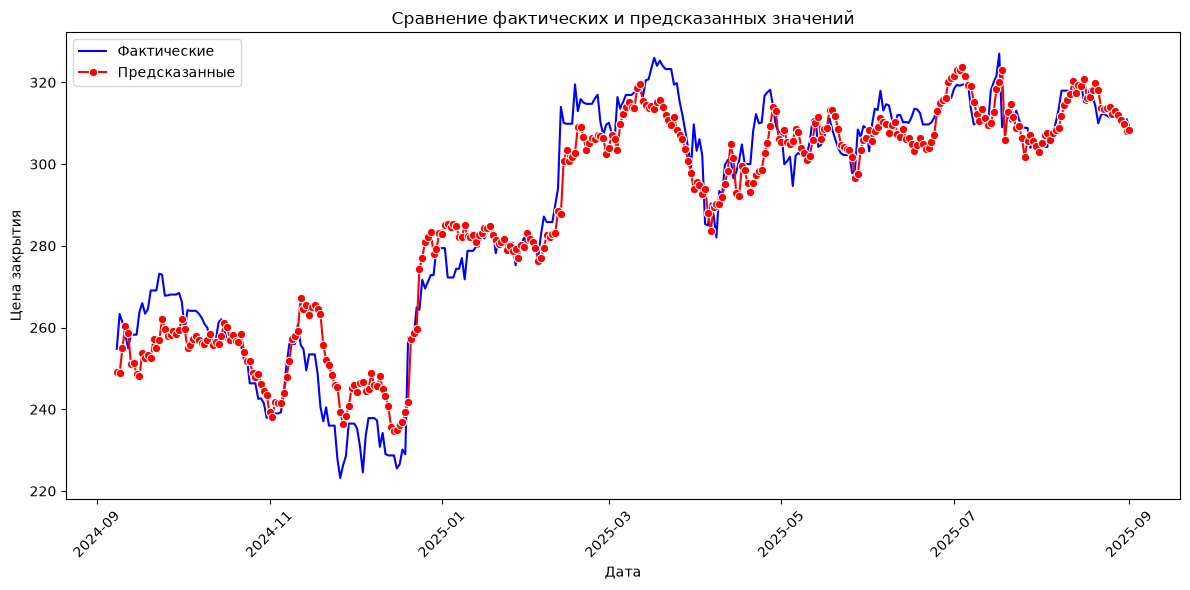

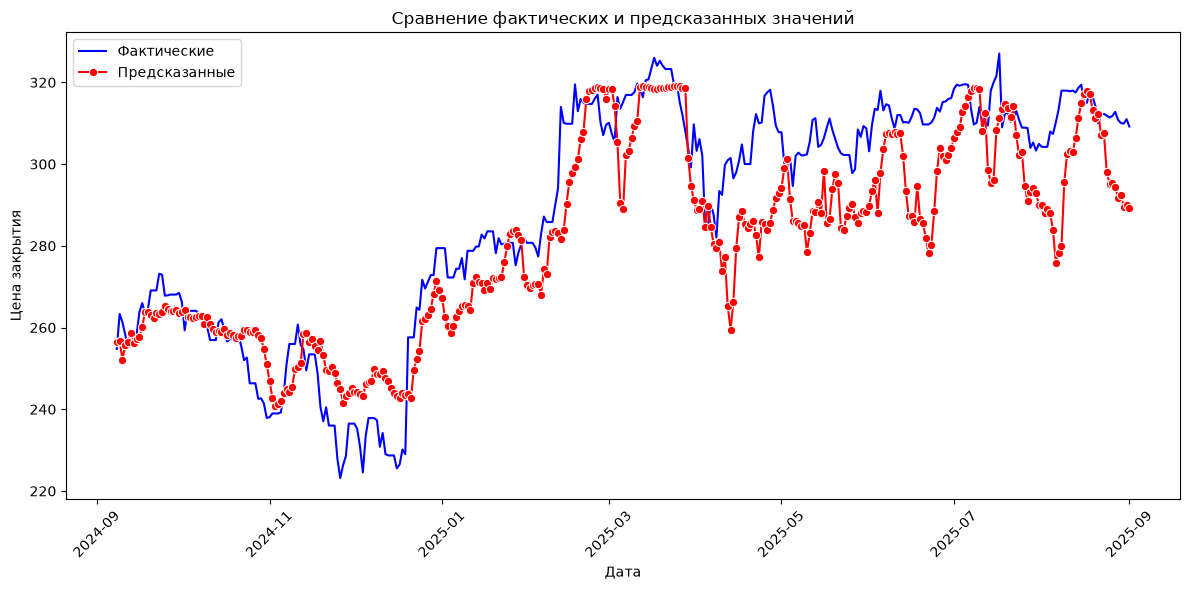

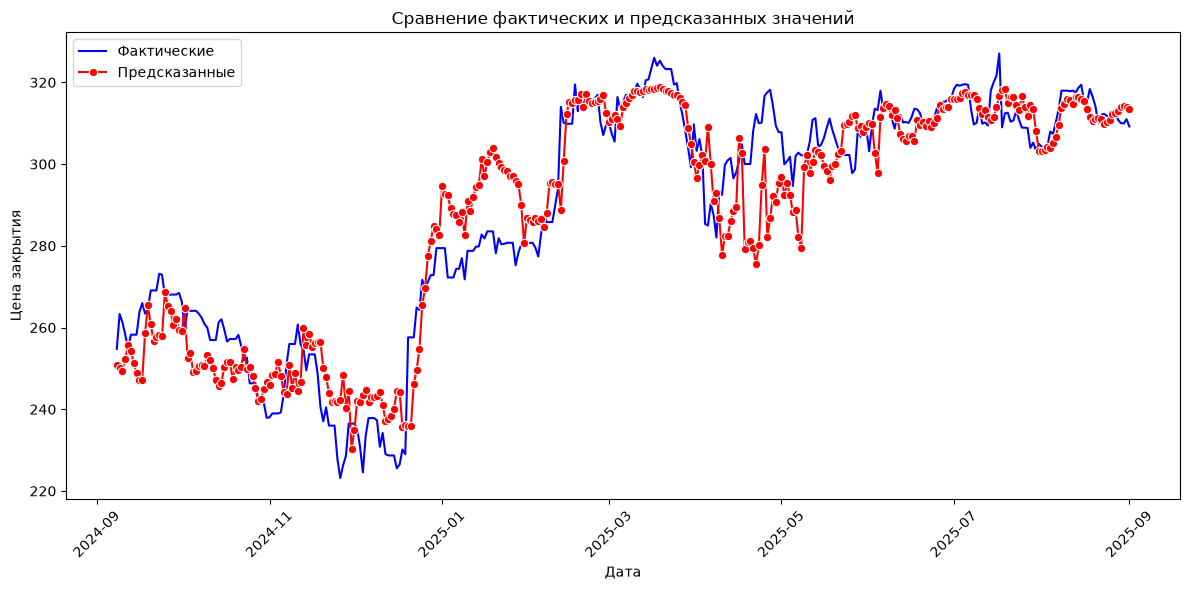

In [27]:
# Визуализация
test_plot(dnn_pred, pd.Series(dnn_y, index=y_test.index[:len(dnn_y)]))
test_plot(lstm_pred, pd.Series(lstm_y, index=y_test.index[len(y_test)-len(lstm_y):]))
test_plot(gru_pred, pd.Series(gru_y, index=y_test.index[len(y_test)-len(gru_y):]))

# Сохранение моделей
Модели можно сохранить с помощью `torch.save`.

In [12]:
torch.save(dnn_model.state_dict(), OUTPUT_DIR / "DNN_model.pt")
torch.save(lstm_model.state_dict(), OUTPUT_DIR / "LSTM_model.pt")
torch.save(gru_model.state_dict(), OUTPUT_DIR / "GRU_model.pt")

In [15]:
class _ShapWrapper(nn.Module):
    """Обёртка: гарантирует, что выход модели имеет форму (batch, 1).

    Нужна, потому что shap.GradientExplainer ожидает 2D-выход,
    а DNN/LSTM/GRU возвращают (batch,) из-за squeeze(-1).
    """
    def __init__(self, model: nn.Module):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        if out.dim() == 1:
            out = out.unsqueeze(-1)
        return out


def compute_shap_gradient(model, X_bg, X_eval, is_recurrent=False):
    """
    SHAP-значения для нейросети через GradientExplainer.
    Для рекуррентных моделей агрегирует по временной оси (среднее).
    Возвращает массив формы (n_eval, n_features).
    """
    model.eval()
    wrapped = _ShapWrapper(model).to(device)
    wrapped.eval()

    bg_t = torch.tensor(X_bg, dtype=torch.float32).to(device)
    ev_t = torch.tensor(X_eval, dtype=torch.float32).to(device)

    explainer = shap.GradientExplainer(wrapped, bg_t)
    sv = explainer.shap_values(ev_t)

    if isinstance(sv, list):
        sv = sv[0]
    sv = np.asarray(sv)

    # На всякий случай: если SHAP вернул (n_eval, n_features, 1) — уберём последнюю ось
    if sv.ndim == 3 and sv.shape[-1] == 1 and not is_recurrent:
        sv = sv[..., 0]

    if is_recurrent:
        # Ожидаем (n_eval, seq_len, n_features); усредняем по времени
        if sv.ndim == 4 and sv.shape[-1] == 1:
            sv = sv[..., 0]
        sv = sv.mean(axis=1)

    return sv


def sample_flat_background(X_scaled, n_bg):
    """Случайная подвыборка плоских признаков."""
    n = min(n_bg, len(X_scaled))
    idx = np.random.RandomState(OPTUNA_SEED).choice(len(X_scaled), n, replace=False)
    return X_scaled[idx]


def sample_seq_background_from_seqs(X_seq, n_bg):
    """Случайная подвыборка уже построенных последовательностей."""
    n = min(n_bg, len(X_seq))
    idx = np.random.RandomState(OPTUNA_SEED).choice(len(X_seq), n, replace=False)
    return X_seq[idx]


def make_feature_split_from_shap(shap_values, feature_names,
                                 threshold=CUMULATIVE_IMPORTANCE_THRESHOLD):
    """
    Разбивает признаки по кумулятивной SHAP-важности:
    selected — минимальный набор, покрывающий threshold суммарной важности,
    deleted  — все остальные.
    """
    mean_abs = np.abs(shap_values).mean(axis=0)
    imp = pd.DataFrame({"feature": feature_names, "shap": mean_abs})
    imp = imp.sort_values("shap", ascending=False).reset_index(drop=True)
    total = imp["shap"].sum()
    cumsum = 0.0
    selected = []
    for _, row in imp.iterrows():
        cumsum += row["shap"]
        selected.append(row["feature"])
        if cumsum / total >= threshold:
            break
    deleted = [f for f in feature_names if f not in selected]
    return selected, deleted, imp


def slice_features(X_train_scaled, X_test_scaled, feature_names, selected):
    """Выбирает столбцы по списку имён признаков."""
    idx = [feature_names.index(f) for f in selected]
    return X_train_scaled[:, idx], X_test_scaled[:, idx]

In [16]:
# --- DNN (плоские входы) ---
dnn_bg = sample_flat_background(X_train_scaled, SHAP_BACKGROUND_SIZE)
n_eval_dnn = min(SHAP_BACKGROUND_SIZE, len(X_test_scaled))
dnn_eval = X_test_scaled[:n_eval_dnn]
dnn_shap_values = compute_shap_gradient(dnn_model, dnn_bg, dnn_eval, is_recurrent=False)

# --- LSTM ---
window_lstm = lstm_study.best_params['window_size']
X_all_lstm, y_all_lstm, lstm_test_start = build_sequences_with_context(
    X_train_scaled, y_train.values, X_test_scaled, y_test.values, window_lstm)
X_train_lstm_seq = X_all_lstm[:lstm_test_start]
X_test_lstm_seq  = X_all_lstm[lstm_test_start:]

lstm_bg = sample_seq_background_from_seqs(X_train_lstm_seq, SHAP_BACKGROUND_SIZE)
n_eval_lstm = min(SHAP_BACKGROUND_SIZE, len(X_test_lstm_seq))
lstm_shap_values = compute_shap_gradient(
    lstm_model, lstm_bg, X_test_lstm_seq[:n_eval_lstm], is_recurrent=True)

# --- GRU ---
window_gru = gru_study.best_params['window_size']
X_all_gru, y_all_gru, gru_test_start = build_sequences_with_context(
    X_train_scaled, y_train.values, X_test_scaled, y_test.values, window_gru)
X_train_gru_seq = X_all_gru[:gru_test_start]
X_test_gru_seq  = X_all_gru[gru_test_start:]

gru_bg = sample_seq_background_from_seqs(X_train_gru_seq, SHAP_BACKGROUND_SIZE)
n_eval_gru = min(SHAP_BACKGROUND_SIZE, len(X_test_gru_seq))
gru_shap_values = compute_shap_gradient(
    gru_model, gru_bg, X_test_gru_seq[:n_eval_gru], is_recurrent=True)

/tmp/ipykernel_2169/823948551.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


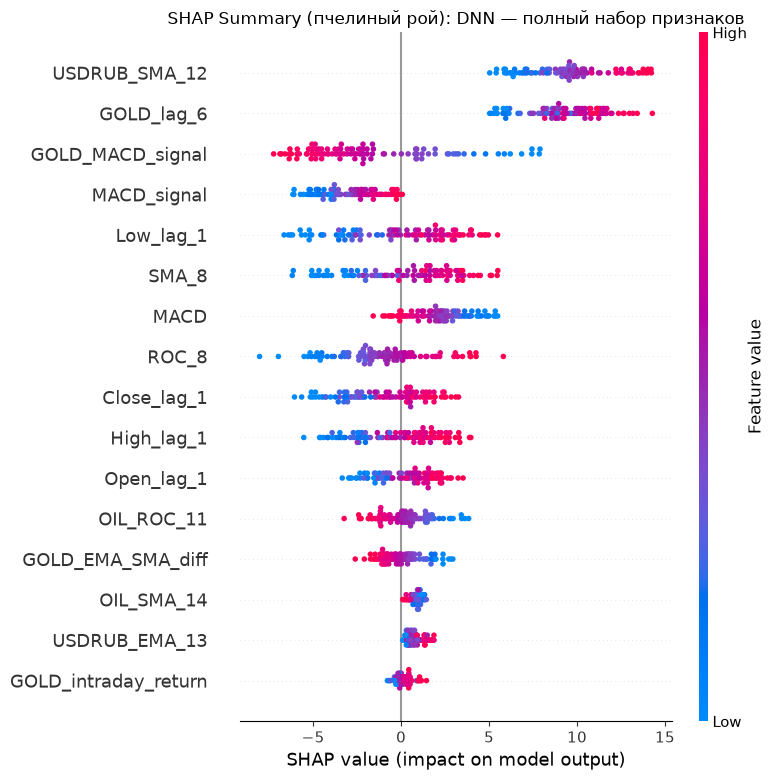

/tmp/ipykernel_2169/823948551.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


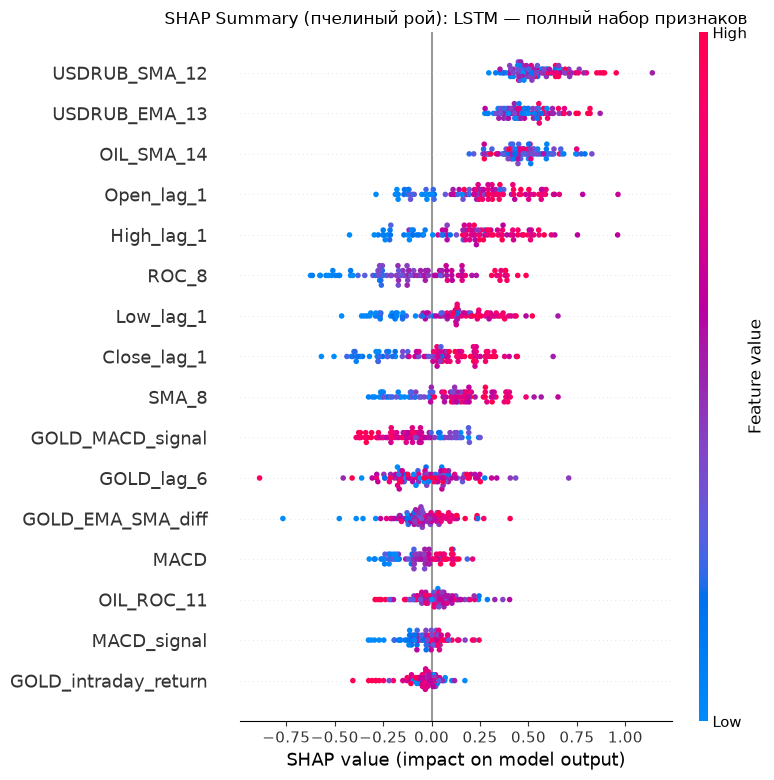

/tmp/ipykernel_2169/823948551.py:16: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


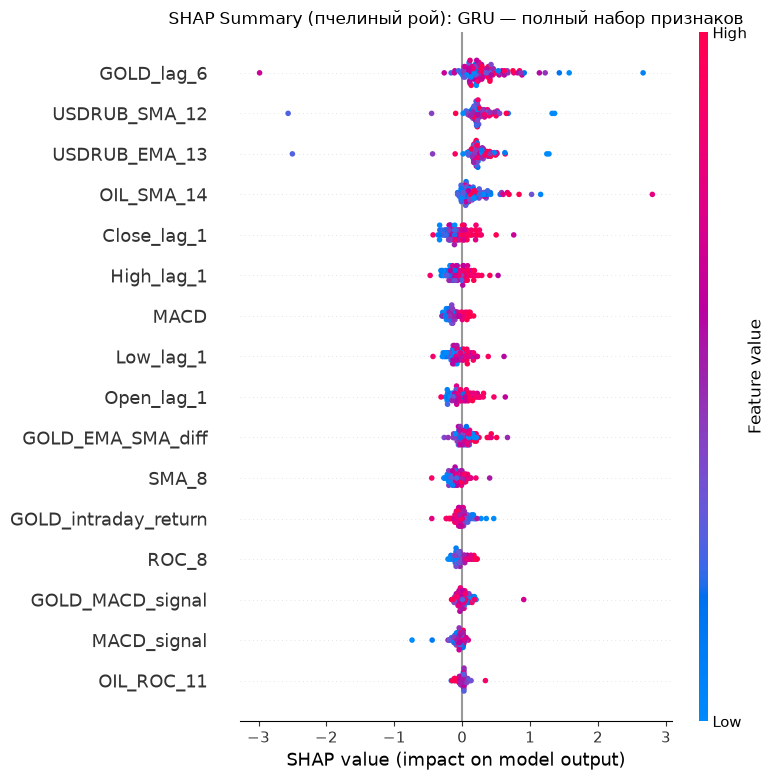

In [17]:
# DNN
shap.summary_plot(
    dnn_shap_values, dnn_eval,
    feature_names=feature_names, show=False)
plt.title("SHAP Summary (пчелиный рой): DNN — полный набор признаков")
plt.tight_layout(); plt.show()

# LSTM — для интерпретации берём последний временной шаг
shap.summary_plot(
    lstm_shap_values, X_test_lstm_seq[:n_eval_lstm, -1, :],
    feature_names=feature_names, show=False)
plt.title("SHAP Summary (пчелиный рой): LSTM — полный набор признаков")
plt.tight_layout(); plt.show()

# GRU
shap.summary_plot(
    gru_shap_values, X_test_gru_seq[:n_eval_gru, -1, :],
    feature_names=feature_names, show=False)
plt.title("SHAP Summary (пчелиный рой): GRU — полный набор признаков")
plt.tight_layout(); plt.show()

In [18]:
dnn_selected,  dnn_deleted,  dnn_imp_df  = make_feature_split_from_shap(dnn_shap_values,  feature_names)
lstm_selected, lstm_deleted, lstm_imp_df = make_feature_split_from_shap(lstm_shap_values, feature_names)
gru_selected,  gru_deleted,  gru_imp_df  = make_feature_split_from_shap(gru_shap_values,  feature_names)

print("DNN : selected =", len(dnn_selected),  "deleted =", len(dnn_deleted))
print("LSTM: selected =", len(lstm_selected), "deleted =", len(lstm_deleted))
print("GRU : selected =", len(gru_selected),  "deleted =", len(gru_deleted))

DNN : selected = 11 deleted = 5
LSTM: selected = 12 deleted = 4
GRU : selected = 13 deleted = 3


In [20]:
# --- Слайсим признаки ---
X_train_dnn_sel, X_test_dnn_sel = slice_features(X_train_scaled, X_test_scaled, feature_names, dnn_selected)
X_train_dnn_del, X_test_dnn_del = slice_features(X_train_scaled, X_test_scaled, feature_names, dnn_deleted)

dnn_sel_data = TrainTestData(X_train_dnn_sel, y_train.values, X_test_dnn_sel, y_test.values)
dnn_del_data = TrainTestData(X_train_dnn_del, y_train.values, X_test_dnn_del, y_test.values)

# --- Optuna на каждом подмножестве ---
dnn_sel_study = create_tpe_study()
dnn_sel_study.optimize(
    partial(dnn_objective, train_test_data=dnn_sel_data, device=device),
    n_trials=N_TRIALS, show_progress_bar=True)

dnn_del_study = create_tpe_study()
dnn_del_study.optimize(
    partial(dnn_objective, train_test_data=dnn_del_data, device=device),
    n_trials=N_TRIALS, show_progress_bar=True)

# --- Обучение лучших и MAPE ---
dnn_sel_model, dnn_sel_pred, dnn_sel_y = train_best_model(
    DNN, dnn_sel_study.best_params, dnn_sel_data, device)
dnn_del_model, dnn_del_pred, dnn_del_y = train_best_model(
    DNN, dnn_del_study.best_params, dnn_del_data, device)

dnn_sel_mape = mean_absolute_percentage_error(dnn_sel_y, dnn_sel_pred)
dnn_del_mape = mean_absolute_percentage_error(dnn_del_y, dnn_del_pred)
print(f"DNN | selected: MAPE = {dnn_sel_mape:.6f}")
print(f"DNN | deleted : MAPE = {dnn_del_mape:.6f}")

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.793289; Test error: 0.308983
{'layer_sizes': [128, 96], 'dropout': 0.2993292420985183, 'learning_rate': 0.0002051338263087451, 'batch_size': 64, 'epochs': 30}
Train error: 0.641037; Test error: 0.191420
{'layer_sizes': [16, 128, 112], 'dropout': 0.10616955533913808, 'learning_rate': 0.0002310201887845295, 'batch_size': 64, 'epochs': 30}
Train error: 0.976090; Test error: 0.749585
{'layer_sizes': [80], 'dropout': 0.06974693032602092, 'learning_rate': 0.0003839629299804173, 'batch_size': 64, 'epochs': 30}
Train error: 0.976182; Test error: 0.609313
{'layer_sizes': [80, 16], 'dropout': 0.3037724259507192, 'learning_rate': 0.00021930485556643703, 'batch_size': 64, 'epochs': 30}
Train error: 0.996078; Test error: 0.945119
{'layer_sizes': [16], 'dropout': 0.34211651325607845, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.797528; Test error: 0.261385
{'layer_sizes': [96], 'dropout': 0.15585553804470548, 'learning_rate': 0.00109682172075

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.819345; Test error: 0.270680
{'layer_sizes': [128, 96], 'dropout': 0.2993292420985183, 'learning_rate': 0.0002051338263087451, 'batch_size': 64, 'epochs': 30}
Train error: 0.567003; Test error: 0.278580
{'layer_sizes': [16, 128, 112], 'dropout': 0.10616955533913808, 'learning_rate': 0.0002310201887845295, 'batch_size': 64, 'epochs': 30}
Train error: 0.976798; Test error: 0.922043
{'layer_sizes': [80], 'dropout': 0.06974693032602092, 'learning_rate': 0.0003839629299804173, 'batch_size': 64, 'epochs': 30}
Train error: 0.975560; Test error: 0.852909
{'layer_sizes': [80, 16], 'dropout': 0.3037724259507192, 'learning_rate': 0.00021930485556643703, 'batch_size': 64, 'epochs': 30}
Train error: 0.995132; Test error: 0.984720
{'layer_sizes': [16], 'dropout': 0.34211651325607845, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.844382; Test error: 0.276904
{'layer_sizes': [96], 'dropout': 0.15585553804470548, 'learning_rate': 0.00109682172075

In [21]:
X_train_lstm_sel, X_test_lstm_sel = slice_features(X_train_scaled, X_test_scaled, feature_names, lstm_selected)
X_train_lstm_del, X_test_lstm_del = slice_features(X_train_scaled, X_test_scaled, feature_names, lstm_deleted)

lstm_sel_data = TrainTestData(X_train_lstm_sel, y_train.values, X_test_lstm_sel, y_test.values)
lstm_del_data = TrainTestData(X_train_lstm_del, y_train.values, X_test_lstm_del, y_test.values)

lstm_sel_study = create_tpe_study()
lstm_sel_study.optimize(
    partial(lstm_objective, train_test_data=lstm_sel_data, device=device),
    n_trials=N_TRIALS, show_progress_bar=True)

lstm_del_study = create_tpe_study()
lstm_del_study.optimize(
    partial(lstm_objective, train_test_data=lstm_del_data, device=device),
    n_trials=N_TRIALS, show_progress_bar=True)

lstm_sel_model, lstm_sel_pred, lstm_sel_y = train_best_model(
    LSTMNet, lstm_sel_study.best_params, lstm_sel_data, device)
lstm_del_model, lstm_del_pred, lstm_del_y = train_best_model(
    LSTMNet, lstm_del_study.best_params, lstm_del_data, device)

lstm_sel_mape = mean_absolute_percentage_error(lstm_sel_y, lstm_sel_pred)
lstm_del_mape = mean_absolute_percentage_error(lstm_del_y, lstm_del_pred)
print(f"LSTM | selected: MAPE = {lstm_sel_mape:.6f}")
print(f"LSTM | deleted : MAPE = {lstm_del_mape:.6f}")

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.818113; Test error: 0.704208
{'window_size': 10, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.2993292420985183, 'bidirectional': True, 'learning_rate': 0.00013066739238053285, 'batch_size': 16, 'epochs': 30}
Train error: 0.818111; Test error: 0.698127
{'window_size': 20, 'hidden_size': 112, 'num_layers': 2, 'dropout': 0.09091248360355031, 'bidirectional': False, 'learning_rate': 0.0011207606211860567, 'batch_size': 64, 'epochs': 30}
Train error: 0.786245; Test error: 0.658244
{'window_size': 9, 'hidden_size': 48, 'num_layers': 2, 'dropout': 0.3925879806965068, 'bidirectional': False, 'learning_rate': 0.0015304852121831463, 'batch_size': 32, 'epochs': 30}
Train error: 0.909656; Test error: 0.855099
{'window_size': 20, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.15230688458668534, 'bidirectional': False, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.294362; Test error: 0.025482
{'window_size': 9, 'hidden_size': 96, 'num_

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.777189; Test error: 0.704975
{'window_size': 10, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.2993292420985183, 'bidirectional': True, 'learning_rate': 0.00013066739238053285, 'batch_size': 16, 'epochs': 30}
Train error: 0.785663; Test error: 0.692999
{'window_size': 20, 'hidden_size': 112, 'num_layers': 2, 'dropout': 0.09091248360355031, 'bidirectional': False, 'learning_rate': 0.0011207606211860567, 'batch_size': 64, 'epochs': 30}
Train error: 0.750744; Test error: 0.658242
{'window_size': 9, 'hidden_size': 48, 'num_layers': 2, 'dropout': 0.3925879806965068, 'bidirectional': False, 'learning_rate': 0.0015304852121831463, 'batch_size': 32, 'epochs': 30}
Train error: 0.889743; Test error: 0.854403
{'window_size': 20, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.15230688458668534, 'bidirectional': False, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.438832; Test error: 0.158290
{'window_size': 9, 'hidden_size': 96, 'num_

In [22]:
X_train_gru_sel, X_test_gru_sel = slice_features(X_train_scaled, X_test_scaled, feature_names, gru_selected)
X_train_gru_del, X_test_gru_del = slice_features(X_train_scaled, X_test_scaled, feature_names, gru_deleted)

gru_sel_data = TrainTestData(X_train_gru_sel, y_train.values, X_test_gru_sel, y_test.values)
gru_del_data = TrainTestData(X_train_gru_del, y_train.values, X_test_gru_del, y_test.values)

gru_sel_study = create_tpe_study()
gru_sel_study.optimize(
    partial(gru_objective, train_test_data=gru_sel_data, device=device),
    n_trials=N_TRIALS, show_progress_bar=True)

gru_del_study = create_tpe_study()
gru_del_study.optimize(
    partial(gru_objective, train_test_data=gru_del_data, device=device),
    n_trials=N_TRIALS, show_progress_bar=True)

gru_sel_model, gru_sel_pred, gru_sel_y = train_best_model(
    GRUNet, gru_sel_study.best_params, gru_sel_data, device)
gru_del_model, gru_del_pred, gru_del_y = train_best_model(
    GRUNet, gru_del_study.best_params, gru_del_data, device)

gru_sel_mape = mean_absolute_percentage_error(gru_sel_y, gru_sel_pred)
gru_del_mape = mean_absolute_percentage_error(gru_del_y, gru_del_pred)
print(f"GRU | selected: MAPE = {gru_sel_mape:.6f}")
print(f"GRU | deleted : MAPE = {gru_del_mape:.6f}")

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.859851; Test error: 0.669629
{'window_size': 10, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.2993292420985183, 'bidirectional': True, 'learning_rate': 0.00013066739238053285, 'batch_size': 16, 'epochs': 30}
Train error: 0.909094; Test error: 0.692700
{'window_size': 20, 'hidden_size': 112, 'num_layers': 2, 'dropout': 0.09091248360355031, 'bidirectional': False, 'learning_rate': 0.0011207606211860567, 'batch_size': 64, 'epochs': 30}
Train error: 0.866924; Test error: 0.658168
{'window_size': 9, 'hidden_size': 48, 'num_layers': 2, 'dropout': 0.3925879806965068, 'bidirectional': False, 'learning_rate': 0.0015304852121831463, 'batch_size': 32, 'epochs': 30}
Train error: 0.950511; Test error: 0.911823
{'window_size': 20, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.15230688458668534, 'bidirectional': False, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.342823; Test error: 0.035255
{'window_size': 9, 'hidden_size': 96, 'num_

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.753149; Test error: 0.668013
{'window_size': 10, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.2993292420985183, 'bidirectional': True, 'learning_rate': 0.00013066739238053285, 'batch_size': 16, 'epochs': 30}
Train error: 0.786409; Test error: 0.694417
{'window_size': 20, 'hidden_size': 112, 'num_layers': 2, 'dropout': 0.09091248360355031, 'bidirectional': False, 'learning_rate': 0.0011207606211860567, 'batch_size': 64, 'epochs': 30}
Train error: 0.761139; Test error: 0.661125
{'window_size': 9, 'hidden_size': 48, 'num_layers': 2, 'dropout': 0.3925879806965068, 'bidirectional': False, 'learning_rate': 0.0015304852121831463, 'batch_size': 32, 'epochs': 30}
Train error: 0.893817; Test error: 0.858042
{'window_size': 20, 'hidden_size': 128, 'num_layers': 3, 'dropout': 0.15230688458668534, 'bidirectional': False, 'learning_rate': 0.0007591104805282694, 'batch_size': 128, 'epochs': 30}
Train error: 0.463586; Test error: 0.160216
{'window_size': 9, 'hidden_size': 96, 'num_

In [23]:
summary_rows = [
    {"model": "DNN",  "subset": "selected", "n_features": len(dnn_selected),  "mape": dnn_sel_mape},
    {"model": "DNN",  "subset": "deleted",  "n_features": len(dnn_deleted),   "mape": dnn_del_mape},
    {"model": "LSTM", "subset": "selected", "n_features": len(lstm_selected), "mape": lstm_sel_mape},
    {"model": "LSTM", "subset": "deleted",  "n_features": len(lstm_deleted),  "mape": lstm_del_mape},
    {"model": "GRU",  "subset": "selected", "n_features": len(gru_selected),  "mape": gru_sel_mape},
    {"model": "GRU",  "subset": "deleted",  "n_features": len(gru_deleted),   "mape": gru_del_mape},
]
nn_subset_summary = pd.DataFrame(summary_rows)
print(nn_subset_summary.to_string(index=False))

model   subset  n_features     mape
  DNN selected          11 0.181859
  DNN  deleted           5 0.154916
 LSTM selected          12 0.033763
 LSTM  deleted           4 0.169758
  GRU selected          13 0.040095
  GRU  deleted           3 0.168049


/tmp/ipykernel_2169/2834548689.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


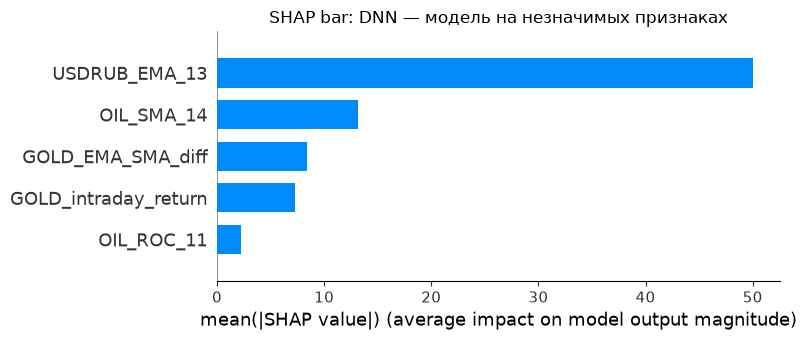

In [24]:
dnn_del_bg = sample_flat_background(X_train_dnn_del, SHAP_BACKGROUND_SIZE)
n_eval_dnn_del = min(SHAP_BACKGROUND_SIZE, len(X_test_dnn_del))
dnn_del_shap = compute_shap_gradient(
    dnn_del_model, dnn_del_bg, X_test_dnn_del[:n_eval_dnn_del], is_recurrent=False)

shap.summary_plot(
    dnn_del_shap, X_test_dnn_del[:n_eval_dnn_del],
    feature_names=dnn_deleted, plot_type="bar", show=False)
plt.title("SHAP bar: DNN — модель на незначимых признаках")
plt.tight_layout(); plt.show()

/tmp/ipykernel_2169/1928770882.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


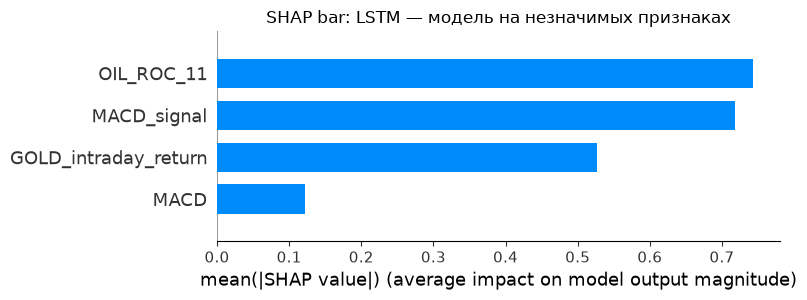

In [25]:
window_lstm_del = lstm_del_study.best_params['window_size']
X_all_lstm_del, _, lstm_del_test_start = build_sequences_with_context(
    X_train_lstm_del, y_train.values, X_test_lstm_del, y_test.values, window_lstm_del)
X_train_lstm_del_seq = X_all_lstm_del[:lstm_del_test_start]
X_test_lstm_del_seq  = X_all_lstm_del[lstm_del_test_start:]

lstm_del_bg = sample_seq_background_from_seqs(X_train_lstm_del_seq, SHAP_BACKGROUND_SIZE)
n_eval_lstm_del = min(SHAP_BACKGROUND_SIZE, len(X_test_lstm_del_seq))
lstm_del_shap = compute_shap_gradient(
    lstm_del_model, lstm_del_bg, X_test_lstm_del_seq[:n_eval_lstm_del], is_recurrent=True)

shap.summary_plot(
    lstm_del_shap, X_test_lstm_del_seq[:n_eval_lstm_del, -1, :],
    feature_names=lstm_deleted, plot_type="bar", show=False)
plt.title("SHAP bar: LSTM — модель на незначимых признаках")
plt.tight_layout(); plt.show()

/tmp/ipykernel_2169/2876776257.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


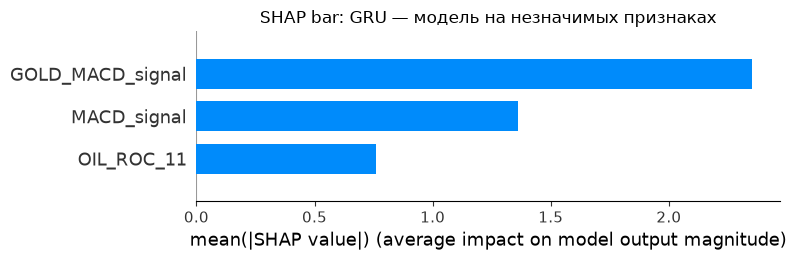

In [26]:
window_gru_del = gru_del_study.best_params['window_size']
X_all_gru_del, _, gru_del_test_start = build_sequences_with_context(
    X_train_gru_del, y_train.values, X_test_gru_del, y_test.values, window_gru_del)
X_train_gru_del_seq = X_all_gru_del[:gru_del_test_start]
X_test_gru_del_seq  = X_all_gru_del[gru_del_test_start:]

gru_del_bg = sample_seq_background_from_seqs(X_train_gru_del_seq, SHAP_BACKGROUND_SIZE)
n_eval_gru_del = min(SHAP_BACKGROUND_SIZE, len(X_test_gru_del_seq))
gru_del_shap = compute_shap_gradient(
    gru_del_model, gru_del_bg, X_test_gru_del_seq[:n_eval_gru_del], is_recurrent=True)

shap.summary_plot(
    gru_del_shap, X_test_gru_del_seq[:n_eval_gru_del, -1, :],
    feature_names=gru_deleted, plot_type="bar", show=False)
plt.title("SHAP bar: GRU — модель на незначимых признаках")
plt.tight_layout(); plt.show()